# 09: Reading a global fit's storage files

**This notebook targets the development stack (LATW `dev` branch).** It reads the storage files of an
installed stock global fit with the development LISA Analysis Tools packages
(`lisa-analysis-tools/install.sh`), not the pip releases.

```bash
git clone https://github.com/lisa-analysis-tools/lisa-analysis-tools.git
bash lisa-analysis-tools/install.sh
```

If the install fails, see the [installation documentation](https://lisa-analysis-tools.github.io/lisa-analysis-tools).
The most likely problem is LAPACK or a similar system library.

If you hit runtime problems, pin the thread counts before the imports:

```python
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
           "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
```

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import lisatools
from lisatools.domains import WDMSignal, TDSettings, WDMSettings, WDMLookupTable
from lisatools.analysiscontainer import AnalysisContainer, AnalysisContainerArray
from lisatools.globalfit.hdfbackend import (GFHDFBackend, GBHDFBackend, ModuleSubBackend,
                                            MBHHDFBackend, EMRIHDFBackend, SOBBHHDFBackend)
from lisatools.sensitivity import (CompositeSensitivityBackend, UnequalArmInstrumentNoise,
                                   LinkDelayTable, GalForTimeModulation)
from lisatools.globalfit.stock.erebor.noise import (read_noise_model_identity, resolve_noise_file,
                                                    make_galfor_log_transform_container)
from lisatools.detector import L1Orbits
from lisatools.wdm_lookup_store import lookup_table_path, resolve_gb_lookup_table
from lisatools.sources.bbh import PhenomTHMTDIWaveform
from lisatools.sources.emri import emri_catalogue_to_waveform_basis
from lisatools.sources.emri.response import (EMRI_INSPIRAL_KWARGS, EMRI_SUM_KWARGS,
                                             EMRI_MODE_SELECTOR_KWARGS)
from lisatools.sources.emri.wdm_direct import EMRIDirectWDM
from lisatools.sources.emri.direct_signal_gen import EMRIDirectWDMSignalGen
from lisatools.sources.sobbh.wdm_direct import SOBBHLookupComputations
from lisatools.response.tdiconfig import TDIConfig
from lisatools.globalfit.recipe import MOJITO_REFERENCE_TIME, gb_catalogue_to_sampling_basis
from lisatools.globalfit.moves.sobbhspecialmove import SOBBHChunkedLikeMove
from lisatools.globalfit.stock.erebor.vgb import load_vgb_catalogue_file
from lisatools.globalfit.stock.erebor.transforms import (
    make_gb_transform_container, make_mbh_transform_container,
    make_sobbh_transform_container, make_emri_transform_container)
from gbgpu.gbcomps import GBWDMComputations
from gbgpu.gbsignalhetcomputations import GBSignalHetComputations
from few.waveform.waveform import GenerateEMRIWaveform

No CuPy


In this tutorial we read the output files of a global-fit run, such as our recent CD1-L runs: the
stored samples of every branch, the run's residual, and the noise model the samples are scored
against. Nothing here builds or runs a fit; it is all postprocessing of files a run has already
written.

A run writes one HDF5 **store**, `<base>_testing.h5` (the `_testing` suffix is a legacy name and may
change). For every saved iteration (a **row**) it holds each branch's **cold chain** (the
temperature-1 walkers): the parameters of every source, which sources are alive (`inds`), and each
walker's joint log-likelihood. Each branch also has a **sub-backend** group in the same file with its
**tempered ensemble** (every rung of its temperature ladder) and its sampler counters. Beside the
store the run writes a **residual snapshot**, `<base>_testing_residual_snapshot.npz`: the data minus
every fitted signal, for every cold walker, at one row.

A production run has seven branches: `gb`, `vgb`, `psd`, `galfor`, `mbh`, `emri`, `sobbh`. A run's
snapshot tar ships a reduced store, `<base>_testing_extract.h5`, which reads like the full store for
the rows it keeps (older rows of the large chains read back as zeros). Either works below.

## The store and its residual

Set `store` and `snapshot` to your run's files. Open the store with `GFHDFBackend` and read one row
of every branch, cold and tempered, with `get_a_sample(row)`. The residual for that row comes from
the snapshot, not from regenerating signals. The snapshot covers one row only (`store_row`), so that
is the row to analyze.

In [2]:
run_dir = "/Users/mlkatz/Research/new_dev/lisa-analysis-tools/gf_prod_9mo_v9/"
store = run_dir + "gf_prod_9mo_testing_extract.h5"
snapshot = run_dir + "gf_prod_9mo_testing_residual_snapshot.npz"
reader = GFHDFBackend(store, read_only=True, sub_backend={
    "gb": GBHDFBackend, "vgb": GBHDFBackend, "psd": ModuleSubBackend, "galfor": ModuleSubBackend,
    "mbh": MBHHDFBackend, "emri": EMRIHDFBackend, "sobbh": SOBBHHDFBackend})
print(reader.iteration, "rows,", reader.nwalkers, "walkers, branches", reader.branch_names)

2104 rows, 4 walkers, branches ['gb', 'vgb', 'psd', 'galfor', 'mbh', 'emri', 'sobbh']


The `sub_backend` dict names each branch's sub-backend reader; without it, `get_a_sample` returns the
cold chain only. The snapshot records its store row (`store_row`), the walker with the highest
log-likelihood (`walker`), and every cold walker's log-likelihood (`lnl`). It belongs to that row
when `lnl` equals the store's cold log-likelihood there exactly.

In [3]:
snap = np.load(snapshot)
row, w = int(snap["store_row"]), int(snap["walker"])
print("store row", row, " walker", w)
print("snapshot matches the store row:", np.array_equal(snap["lnl"], reader.get_log_like()[row, 0]))

store row 2103  walker 2
snapshot matches the store row: True


`get_a_sample(row)` returns that row of every branch. `state.branches_coords[name]` is
`(1, nwalkers, nleaves_max, ndim)` (the leading 1 is the cold temperature),
`state.branches_inds[name]` marks the alive sources, and `state.log_like` is `(1, nwalkers)`.
`reader.key_order` names each branch's sampling-basis columns; `galfor` and `vgb` store column
numbers only, and their sections name them.

In [4]:
row = 2010
w = 1

In [5]:
state = reader.get_a_sample(row)
for name in reader.branch_names:
    alive = state.branches_inds[name][0, w].sum()
    print(f"{name:6s} ndim {reader.ndims[name]:2d}  alive on walker {w}: {alive:4d}  basis:", *reader.key_order[name])
print("cold log-likelihood of walker", w, ":", state.log_like[0, w])

gb     ndim  9  alive on walker 1: 3404  basis: dist f0 Mc phi0 cos_iota psi alpha sin_delta fdot_astro_ratio
vgb    ndim  6  alive on walker 1:   55  basis: 0 1 2 3 4 5
psd    ndim  2  alive on walker 1:    1  basis: $S_{\rm oms}$ $S_{\rm tm}$
galfor ndim  5  alive on walker 1:    1  basis: 0 1 2 3 4
mbh    ndim 11  alive on walker 1:    6  basis: logM Q s1z s2z dist phi_ref cos_iota psi alpha sin_delta t_plunge
emri   ndim 12  alive on walker 1:    8  basis: logm1 m2 a p0 e0 dist qS phiS qK phiK Phi_phi0 Phi_r0
sobbh  ndim 11  alive on walker 1:    6  basis: logm1 logm2 s1 s2 dist cosinc f_low phiS cosqS psi phi0
cold log-likelihood of walker 1 : 158055311.63622433


The data and residuals live on the run's WDM grid (its active band and time span).
`read_domain_settings()` rebuilds the grid and `WDMSignal` places an array on it. Top: the data.
Bottom: the residual of walker `w`. What the fit has captured, the galactic binaries across the mHz
band and the vertical streaks of black-hole mergers, is missing from the residual.

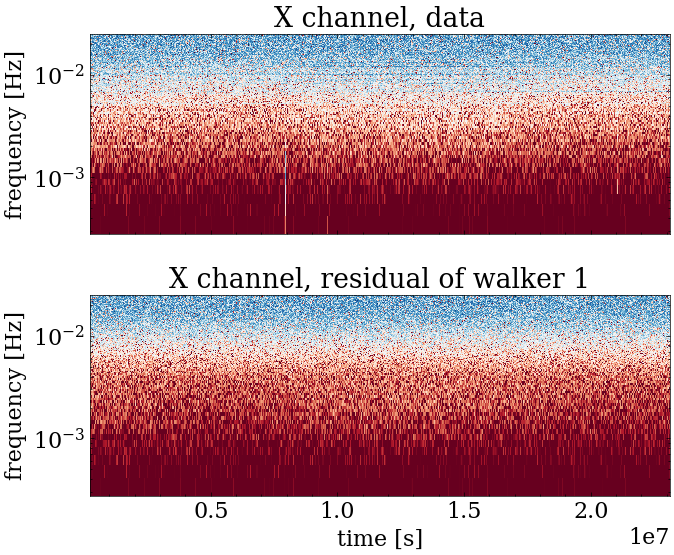

In [6]:
plt.rcParams['text.usetex'] = False
settings = reader.read_domain_settings()
data = WDMSignal(snap["data"].astype(np.float64), settings)
residual = WDMSignal(snap["residuals"][w].astype(np.float64), settings)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 6))
for ax, signal, label in zip(axes, [data, residual], ["data", f"residual of walker {w}"]):
    signal.heatmap(index=0, mag=True, log=True, fig=fig, ax=ax, vmin=-22, vmax=-19)
    ax.set(title=f"X channel, {label}", ylabel="frequency [Hz]", yscale="log")
fig.subplots_adjust(hspace=0.3)
axes[-1].set_xlabel("time [s]")
plt.show()

### More info: the layout on disk, the snapshot's limits, memory

Everything sits under the store's `global_fit` group:

| path | shape | holds |
|---|---|---|
| `chain/<branch>` | `(rows, 1, 1, nwalkers, nleaves_max, ndim)` | cold chain (`get_chain()`) |
| `inds/<branch>` | `(rows, 1, 1, nwalkers, nleaves_max)` | alive sources (`get_inds()`) |
| `log_like` | `(rows, 1, 1, nwalkers)` | joint cold log-likelihood (`get_log_like()`) |
| `key_order`, `ndims`, `nleaves_max` | attributes | sampling basis and sizes of each branch |
| `domain_settings` | group | the WDM grid (`read_domain_settings()`) |
| `noise_model_identity` | attributes | what the noise model was built from (next section) |
| `recipe/<stage>` | attributes | the stages and the rows where each started and finished |
| `sub_backend/<branch>/chain`, `inds` | `(rows, ntemps, nwalkers, nleaves_max[, ndim])` | the tempered ensemble |
| `sub_backend/<branch>/log_like` | `(rows, ntemps, nwalkers)` | log-likelihood of every rung |
| `sub_backend/<branch>/betas`, `betas_all`, `band_*` | per row | the temperature ladder: one per branch, one per source, or one per GB band |
| `sub_backend/<branch>/d_h`, `h_h` | `(rows, nwalkers, nleaves_max)` | per-source inner products, used in the source sections |

The two singleton axes of the cold datasets are the sampler and the temperature; the readers drop
the sampler axis. Datasets are allocated for the full run up front; only the first
`reader.iteration` rows are written, and every reader method stops there.

The snapshot holds ONE state, overwritten every `GF_RESIDUAL_SNAPSHOT_EVERY` rows (default 3), so
only `store_row` has a stored residual. The arrays are float32: a
log-likelihood recomputed from them matches the stored one to about a hundredth of a nat, not to
machine precision. The row check uses exact equality because these log-likelihoods are of order
1e8, where `np.allclose`'s default relative tolerance (1e-5) spans thousands of nats and accepts
neighbouring rows.

Memory: `get_chain()` reads every row of every branch. On a full production store the GB chain
alone is rows x walkers x 20000 x 9 doubles (11 GB for 2000 rows and 4 walkers), so read one row with
`get_a_sample(row)`, one branch with `get_chain(branch_names=[name])`, or a range of rows with
`get_value("chain", slice_vals=slice(a, b))`; the sub-backends take the same `slice_vals`
(`reader.sub_backend[name].get_value("chain", slice_vals=...)`).

## The instrument noise (psd)

The `psd` branch samples the two instrument noise levels, `Soms_d` (optical metrology) and `Sa_a`
(test-mass acceleration), one entry per walker. With the `galfor` foreground they set the noise
covariance every source is scored against. This section reads them, rebuilds that covariance from
the store's noise-model identity record, and recomputes the stored log-likelihood.

Soms_d, Sa_a of walker 1 at row 2010 : [1.49958152e-11 3.08141705e-15]


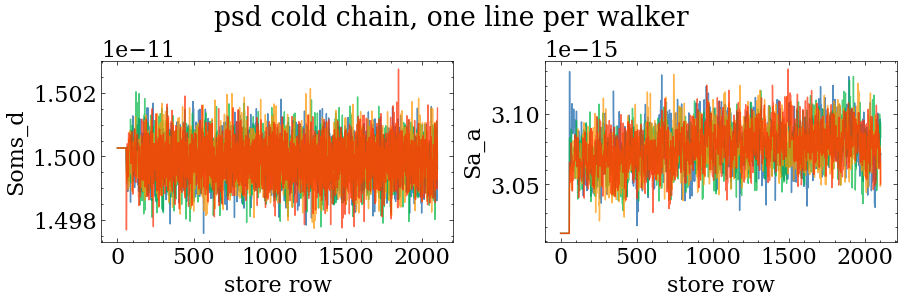

In [7]:
print("Soms_d, Sa_a of walker", w, "at row", row, ":", state.branches_coords["psd"][0, w, 0])
psd_chain = reader.get_chain(branch_names=["psd"])["psd"][:, 0, :, 0]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
for i, label in enumerate(["Soms_d", "Sa_a"]):
    axes[i].plot(psd_chain[:, :, i], alpha=0.7)
    axes[i].set_xlabel("store row")
    axes[i].set_ylabel(label)
fig.suptitle("psd cold chain, one line per walker")
plt.show()

Stages that hold the noise fixed leave this trace flat. The tempered information is the psd move's
own temperature ladder, `state.sub_states["psd"]`: `coords` is `(ntemps, nwalkers, 1, 2)`, `betas`
holds the inverse temperatures, and `log_like` the `(ntemps, nwalkers)` log-likelihood of every
rung. 

In [8]:
psd_sub = state.sub_states["psd"]
print("coords", psd_sub.coords.shape, " log_like", psd_sub.log_like.shape)
print("betas", psd_sub.betas)
print("log_like of walker", w, "on each rung", psd_sub.log_like[:, w])

coords (12, 4, 1, 2)  log_like (12, 4)
betas [1.         0.59315045 0.35171528 0.20823968 0.12272817 0.07265383
 0.04311452 0.02552537 0.01516489 0.00893953 0.00491192 0.        ]
log_like of walker 1 on each rung [1.58055275e+08 1.58055275e+08 1.58055273e+08 1.58055265e+08
 1.58055274e+08 1.58055274e+08 1.58055230e+08 1.58055146e+08
 1.58055194e+08 1.58055205e+08 1.58054835e+08 1.58043462e+08]


The model is a `CompositeSensitivityBackend`. Called with one walker's noise parameters, it returns
that walker's `CompositeSensitivityMatrix`: the 3x3 XYZ covariance of every WDM pixel, the sum of an
instrument component and a galactic-foreground component. Production runs use
`UnequalArmInstrumentNoise`, TDI-2 noise with the six link delays of the real orbit, averaged over
each WDM time column, so the covariance changes as the arms breathe. The foreground is modulated in
time by `GalForTimeModulation`, as the galaxy's signal rises and falls with the constellation's
orientation. The basic sensitivity matrix is in [`04`](04_Foundations.ipynb) §"Sensitivity".

The run records which pieces it used in a **noise-model identity** record in the store: the
instrument class, the WDM PSD method, the data epoch `data_t0` that aligns the delay and
modulation tables with the WDM grid, and the sampling basis of each noise branch. The backend is
rebuilt from it.

In [9]:
ident = read_noise_model_identity(store)
ident

{'coarse_Q': 1,
 'coarse_mode': 'off',
 'coarse_use_ws': True,
 'data_t0': 97729939.827664,
 'galfor_log_sampling': True,
 'galfor_modulation': 'modulation_unequal.dat',
 'galfor_modulation_digest': '2fd5af9aaf893724',
 'galfor_modulation_t0': 97729939.827664,
 'instrument_component': 'UnequalArmInstrumentNoise',
 'ltts_digest': 'f1f3f00ea5d9cf13',
 'psd_log_sampling': False,
 'unequal_arm': True,
 'wdm_psd_method': 'layer_calibrated'}

`resolve_noise_file` finds the mojito L1 NOISE brick in the mojito data folder (the cache the data
loader fills); only its `/ltts` group is read. The foreground modulation table ships with the
lisatools package (`lisatools/galfor_modulation/`), and the store records its file name, which
`GalForTimeModulation` resolves to that packaged copy. The stride, one
delay sample in 200, is the production `UNEQUAL_ARM_STRIDE`.

In [10]:
mojito_dir = os.path.expanduser("~/.mojito_cache/brickmarket/mojito_light_v1_0_0")
modulation_file = ident["galfor_modulation"]  # a bare name: the table packaged with lisatools
ltts = LinkDelayTable.from_l1_file(resolve_noise_file(mojito_dir), stride=200, data_t0=ident["data_t0"])
backend = CompositeSensitivityBackend(
    settings, tdi_generation=2,
    instrument_component_cls=UnequalArmInstrumentNoise,
    instrument_component_kwargs=dict(ltts=ltts),
    wdm_psd_method=ident["wdm_psd_method"],
    galfor_modulation=GalForTimeModulation(modulation_file, t0=ident["galfor_modulation_t0"]),
)

Each branch's row goes from its sampling basis to the model's parameters before the call; the
identity record says which basis each noise branch used. Production runs sample `psd` linearly
(`psd_log_sampling` False, no transform) and `galfor` in log10 (`galfor_log_sampling` True, through
`make_galfor_log_transform_container()`, explained in the galfor section).

The figure compares the model with the residual on the X channel. In the real WDM basis the
log-likelihood is `-1/2 sum r C^-1 r - 1/2 sum log det C` over the pixels, so a pure-noise residual
has `<r_X^2> = C_XX` in every pixel, and their time averages are directly comparable.

psd (Soms_d, Sa_a): [1.49958152e-11 3.08141705e-15]
galfor (amp, fk, alpha, f_1, f_2): [1.26749418e-44 9.29035074e-03 2.38253050e+00 2.36223977e-03
 1.80253987e-03]


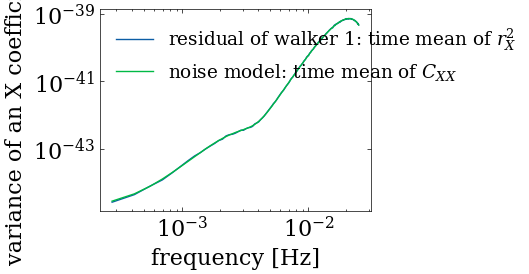

In [11]:
galfor_transform = make_galfor_log_transform_container()
psd = state.branches_coords["psd"][0, w, 0]
galfor = galfor_transform.both_transforms(state.branches_coords["galfor"][0, w, 0])
sens = backend(f"walker_{w}", psd, galfor_params=galfor)
print("psd (Soms_d, Sa_a):", psd)
print("galfor (amp, fk, alpha, f_1, f_2):", galfor)

plt.loglog(settings.f_arr, (residual.arr[0] ** 2).mean(axis=-1), label=f"residual of walker {w}: time mean of $r_X^2$")
plt.loglog(settings.f_arr, sens.sens_mat[0, 0].mean(axis=-1), label="noise model: time mean of $C_{XX}$")
plt.xlabel("frequency [Hz]")
plt.ylabel("variance of an X coefficient")
plt.legend(loc="upper left", fontsize="small")
plt.show()

Where the residual sits above the model, power is left unfit; where it sits below, the noise model
is too loud.

Scoring the residual with the rebuilt covariance gives back the stored cold log-likelihood of walker
`w` (same row, same walker), up to the float32 rounding of the snapshot.
`likelihood(noise_only=True)` is the normalization term `-1/2 sum log det C`.

In [12]:
ac = AnalysisContainer(residual, sens)
lnl = ac.likelihood()
print("rebuilt log-likelihood:", lnl)
print("stored, store row     :", state.log_like[0, w])
print("stored, snapshot      :", snap["lnl"][w])
print("rebuilt - stored      :", lnl - state.log_like[0, w])
print("noise-only term       :", ac.likelihood(noise_only=True))

rebuilt log-likelihood: 158055612.147588
stored, store row     : 158055311.63622433
stored, snapshot      : 158055613.0991508
rebuilt - stored      : 300.5113636851311
noise-only term       : 159763975.36713213


## The galactic foreground (galfor)

The `galfor` branch samples the confusion noise of the unresolvable galactic binaries,
one entry per walker. Its five parameters set the spectrum of `HyperbolicTangentGalacticForeground`,
$S(f) = \frac{A}{2} f^{-7/3} e^{-(f/f_1)^\alpha} [1 + \tanh((f_k - f)/f_2)]$, which
`GalForTimeModulation` modulates in time. Production runs sample the amplitude and the three
frequencies as log10 and `alpha` linearly; `make_galfor_log_transform_container()` maps a stored row
to the model's values, and its `input_basis` names the stored columns.

In [13]:
print(galfor_transform.input_basis, state.branches_coords["galfor"][0, w, 0])
print(galfor_transform.output_basis, galfor)
galfor_sub = state.sub_states["galfor"]
print("betas", galfor_sub.betas)
print("log_like of walker", w, "on each rung, minus the cold rung:", galfor_sub.log_like[:, w] - galfor_sub.log_like[0, w])

['log10_amp', 'log10_fk', 'alpha', 'log10_f_1', 'log10_f_2'] [-43.89705403  -2.03196789   2.3825305   -2.62667602  -2.74411512]
['amp', 'fk', 'alpha', 'f_1', 'f_2'] [1.26749418e-44 9.29035074e-03 2.38253050e+00 2.36223977e-03
 1.80253987e-03]
betas [1.         0.71985666 0.52193645 0.37603318 0.27094634 0.19501076
 0.14059786 0.10127332 0.07288342 0.05258746 0.03562702 0.        ]
log_like of walker 1 on each rung, minus the cold rung: [ 0.00000000e+00 -4.92703402e+00 -3.36025536e-01 -1.04619155e+01
 -8.75166333e+00 -1.54111640e+01 -1.94358014e+01 -2.69433651e+01
 -2.43699951e+01 -6.42040587e+01 -1.09737187e+02 -9.55996628e+04]


The foreground is one component of the psd section's `backend`: called without `galfor_params`,
it returns the instrument noise alone. The figure compares the time-averaged X-channel covariance with
and without the foreground.

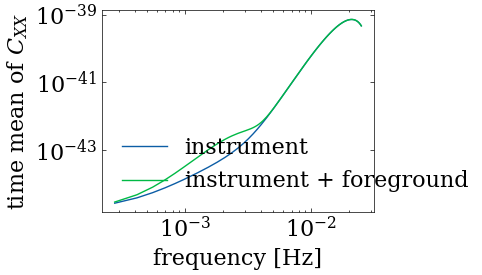

log-likelihood with the foreground   : 158055612.147588


In [14]:
sens_instrument = backend(f"walker_{w}_instrument", psd)
plt.loglog(settings.f_arr, sens_instrument.sens_mat[0, 0].mean(axis=-1), label="instrument")
plt.loglog(settings.f_arr, sens.sens_mat[0, 0].mean(axis=-1), label="instrument + foreground")
plt.xlabel("frequency [Hz]")
plt.ylabel("time mean of $C_{XX}$")
plt.legend()
plt.show()
print("log-likelihood with the foreground   :", AnalysisContainer(residual, sens).likelihood())

## Galactic binaries (gb)

The `gb` branch fits thousands of galactic binaries, each a source with the nine columns of
`reader.key_order["gb"]` (`f0` in mHz). Each source section follows one pattern: take the loudest
source `k` on walker `w` by the `<h|h>` the run stored for it, read its tempered information, map it
through the branch's transform, generate its template on the run's WDM grid, and score it against
the residual with the psd section's `sens`.

In [15]:
gb_sub = state.sub_states["gb"]
k = np.nanargmax(gb_sub.h_h[w])
print(state.branches_inds["gb"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
for name, value in zip(reader.key_order["gb"], state.branches_coords["gb"][0, w, k]):
    print(f"{name:>16s} {value: .6g}")

3404 sources alive on walker 1   loudest: source 2752
            dist  1.29082
              f0  5.16798
              Mc  0.506077
            phi0  4.9994
        cos_iota -0.662254
             psi  1.6083
           alpha  2.03608
       sin_delta -0.899931
fdot_astro_ratio  1.79503


GB tempering runs per frequency band, each band with its own temperature ladder.
`gb_sub.band_info` holds the band edges, the inverse temperatures of every band's ladder
(`band_temps`, bands x rungs) and the number of sources on every rung of every band
(`band_num_binaries`, rungs x walkers x bands); its per-row arrays keep a leading row axis of
length one. The tempered chain itself (`gb_sub.coords`) is the cold chain times the number of
rungs; these summaries are what to read. The figure shows the cold rung's sources per band.

1232 bands; inverse temperatures of source k's band: [1.00000000e+00 8.22136418e-01 6.97285980e-01 5.70937986e-01
 4.81121836e-01 3.97326334e-01 3.32710932e-01 2.76728364e-01
 2.35804373e-01 1.91443614e-01 1.61317220e-01 1.33173758e-01
 1.12721554e-01 9.24522590e-02 7.85165334e-02 6.41091848e-02
 5.47055993e-02 4.43869229e-02 3.77361648e-02 3.08164835e-02
 2.60868204e-02 2.14312644e-02 1.79013122e-02 1.00000000e-04]
sources per rung on walker 1 : [3404. 3152. 3107. 2691. 2460. 2091. 1905. 1660. 1503. 1317. 1262. 1094.
 1064.  965.  985.  919. 1032. 1026. 1100. 1186. 1230. 1444. 1482. 4417.]


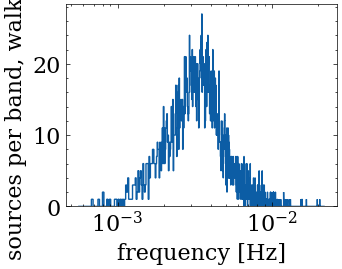

In [16]:
band_info = gb_sub.band_info
band = np.searchsorted(band_info["band_edges"], 1e-3 * state.branches_coords["gb"][0, w, k, 1]) - 1
print(len(band_info["band_edges"]) - 1, "bands; inverse temperatures of source k's band:", band_info["band_temps"][0, band])
print("sources per rung on walker", w, ":", band_info["band_num_binaries"][0, :, w].sum(axis=-1))
plt.stairs(band_info["band_num_binaries"][0, 0, w], band_info["band_edges"])
plt.xscale("log")
plt.xlabel("frequency [Hz]")
plt.ylabel(f"sources per band, walker {w}")
plt.show()

The stock transform `make_gb_transform_container(use_chirp_mass=True, use_fdot_astro=True,
use_distance=True)` maps the stored columns to the generator's nine physical parameters: the
amplitude from distance, `f0` and `Mc`; `f0` in Hz; `fdot` from the GR chirp of `Mc` times
`1 + fdot_astro_ratio`; `fddot` = 0; the sign-flipped `phi0`; the inclination; `psi`; and the ICRS
sky as right ascension and declination. The output columns keep the sampling names: `cos_iota`
holds the inclination and `sin_delta` the declination.

In [17]:
gb_transform = make_gb_transform_container(use_chirp_mass=True, use_fdot_astro=True, use_distance=True)
print("input basis matches the store:", list(gb_transform.input_basis) == list(reader.key_order["gb"]))
gb_k = gb_transform.both_transforms(state.branches_coords["gb"][0, w, k])
for name, value in zip(gb_transform.output_basis, gb_k):
    print(f"{name:>10s} {value: .6g}")

input basis matches the store: True
         A  4.42307e-22
        f0  0.00516798
      fdot  2.14802e-15
     fddot  0
      phi0 -4.9994
  cos_iota  2.29462
       psi  1.6083
     alpha  2.03608
 sin_delta -1.11961


Every source's response uses the run's orbits: `L1Orbits` reads the spacecraft positions and the
six link delays from the same L1 noise brick in the ICRS frame the run samples in. The brick
tabulates the link delays every 2.5 s for two years (1.2 GB); they change over months, so keep one
sample in 200 before the orbits are first used, as the noise model does. The source sections below
reuse these `orbits`.

In [18]:
orbits = L1Orbits(resolve_noise_file(mojito_dir), frame="icrs")
orbits.ltt, orbits.ltt_t = orbits.ltt[::200], orbits.ltt_t[::200]
orbits.ltt_dt *= 200

The run builds its GB templates with `GBWDMComputations` (gbgpu), which computes a binary's TDI-2
XYZ response directly on the WDM grid, heterodyned around the source's frequency in chunks. It
scores sources inside the in-model moves with `GBSignalHetComputations`, a signal-heterodyne
engine built around that comp (`for_band_engine`) whose per-source reference and anchor come from a
GB WDM lookup table. The keyword arguments below are the run's production settings. As in the run,
the comp gets a copy of the WDM grid whose `t0` is the data's absolute start time, and `t_ref` is
the epoch the catalogue parameters are defined at. `resolve_gb_lookup_table(table_dir=run_dir)`
finds the GB table in the run folder, or builds it there (it is small). `fill_global_wdm` adds the
template into a zeroed `WDMSignal`.

In [19]:
gb_settings = WDMSettings(*settings.args, **{**settings.kwargs, "t0": ident["data_t0"]})
gb_comp = GBWDMComputations(gb_settings, t_ref=MOJITO_REFERENCE_TIME, Nt_sub=256, n_pad=32, N_sparse=256,
                            N_cp_sig=48, N_cp_orbit=32, orbits=orbits, tdi_config="2nd generation", tdi_type="XYZ")
gb_engine = GBSignalHetComputations.for_band_engine(
    gb_comp, nt_layer=180, n_sparse_fd=1024, max_r=0.0, n_cp_build=256, v3_n_nodes=64, v4_knots=128,
    v4_band=16, v5=1, tukey_alpha=0.01, lookup_table=resolve_gb_lookup_table(table_dir=run_dir),
    anchor_engine="lookup")
h = WDMSignal(np.zeros((3, *settings.basis_shape_active)), settings)
gb_comp.fill_global_wdm(gb_k, h)

`d = residual + h` is the data with every other fitted signal removed. The engine scores a source
against a buffer holding `d` and the noise model: `setup_in_model` builds the heterodyne reference
at the source's parameters, and `get_ll_wdm` leaves `<d|h>` and `<h|h>` (the squared optimal SNR)
in `d_h_out` and `h_h_out`; the source adds `<d|h> - <h|h>/2` to the log-likelihood. The run
stored the same two numbers for this source (`gb_sub.d_h`, `gb_sub.h_h`) when it last moved it,
against the residual and noise of that moment, so they agree closely rather than exactly.

In [20]:
buffer = AnalysisContainerArray(AnalysisContainer(residual + h, sens))
gb_engine.setup_in_model(buffer, gb_k[None], np.array([0]))
gb_engine.get_ll_wdm(gb_k[None], buffer, data_index=np.array([0]))
h_h, d_h = float(gb_engine.h_h_out[0]), float(gb_engine.d_h_out[0])
gb_engine.clear_in_model()
print(f"<h|h> {h_h:12.2f}   stored {gb_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {gb_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h>    103022.96   stored    102980.30
<d|h>    103003.99   stored    103334.49
optimal SNR 321.0, log-likelihood contribution 51492.5


## Verification galactic binaries (vgb)

The `vgb` branch fits the known verification binaries. Their frequency and sky position come from
the VGB catalogue and stay fixed, so each source samples six columns: `dist, phi0, cos_iota, psi,
Mc, fdot_astro_ratio`. The branch has its own transform: the GB container on those six inputs, with
one fill per source for `f0`, `alpha` and `sin_delta`. The template comp and the scoring engine are the gb section's `gb_comp` and `gb_engine`: the run builds the VGB branch's own with the same settings and the same lookup table.

In [21]:
vgb_sub = state.sub_states["vgb"]
k = np.nanargmax(vgb_sub.h_h[w])
vgb_basis = ["dist", "phi0", "cos_iota", "psi", "Mc", "fdot_astro_ratio"]
print(state.branches_inds["vgb"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
for name, value in zip(vgb_basis, state.branches_coords["vgb"][0, w, k]):
    print(f"{name:>16s} {value: .6g}")
print("tempered coords", vgb_sub.coords.shape, "  band ladders", vgb_sub.band_info["band_temps"][0].shape)

55 sources alive on walker 1   loudest: source 13
            dist  1.12406
            phi0  5.85124
        cos_iota  0.473195
             psi  1.3353
              Mc  0.777473
fdot_astro_ratio -2.6027
tempered coords (8, 4, 55, 6)   band ladders (58, 8)


`gb_catalogue_to_sampling_basis` turns the catalogue into rows of the 8-column GB basis
`ln A, f0 [mHz], fdot, phi0, cos_iota, psi, alpha, sin_delta`, in the run's source order; columns
1, 6 and 7 are the fills. `both_transforms` takes `leaf_inds` to pick each row's fills.

In [23]:
rows = gb_catalogue_to_sampling_basis(load_vgb_catalogue_file(mojito_dir)["vgb"])
vgb_transform = make_gb_transform_container(
    use_chirp_mass=True, use_fdot_astro=True, use_distance=True,
    input_basis=vgb_basis,
    fill_dict=[{"f0": r[1], "alpha": r[6], "sin_delta": r[7]} for r in rows])
vgb_k = vgb_transform.both_transforms(state.branches_coords["vgb"][0, w, k][None], leaf_inds=np.array([k]))[0]
for name, value in zip(vgb_transform.output_basis, vgb_k):
    print(f"{name:>10s} {value: .6g}")

         A  4.91864e-22
        f0  0.0016835
      fdot -4.12314e-17
     fddot  0
      phi0 -5.85124
  cos_iota  1.07788
       psi  1.3353
     alpha  2.50942
 sin_delta  0.771178


In [24]:
h = WDMSignal(np.zeros((3, *settings.basis_shape_active)), settings)
gb_comp.fill_global_wdm(vgb_k, h)
buffer = AnalysisContainerArray(AnalysisContainer(residual + h, sens))
gb_engine.setup_in_model(buffer, vgb_k[None], np.array([0]))
gb_engine.get_ll_wdm(vgb_k[None], buffer, data_index=np.array([0]))
h_h, d_h = float(gb_engine.h_h_out[0]), float(gb_engine.d_h_out[0])
gb_engine.clear_in_model()
print(f"<h|h> {h_h:12.2f}   stored {vgb_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {vgb_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h>      2657.33   stored      2655.78
<d|h>      2669.74   stored      2691.76
optimal SNR 51.5, log-likelihood contribution 1341.1


## Massive black-hole binaries (mbh)

The `mbh` branch samples each merger in the eleven columns of `reader.key_order["mbh"]`: log total
mass, mass ratio `Q = m1/m2`, aligned spins, distance in Gpc, phase, `cos_iota`, polarization, ICRS
sky, and the merger time `t_plunge` counted from `MOJITO_REFERENCE_TIME`. Each source has its own
temperature ladder.

In [25]:
mbh_sub = state.sub_states["mbh"]
k = np.nanargmax(mbh_sub.h_h[w])
print(state.branches_inds["mbh"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
print("tempered coords", mbh_sub.coords.shape, "  log_like", mbh_sub.log_like.shape)
print("inverse temperatures of source", k, ":", mbh_sub.betas_all[k])
print("log_like of walker", w, "on each rung, minus the cold rung:", mbh_sub.log_like[k, :, w] - mbh_sub.log_like[k, 0, w])

6 sources alive on walker 1   loudest: source 2
tempered coords (8, 4, 6, 11)   log_like (6, 8, 4)
inverse temperatures of source 2 : [1.         0.71662902 0.51397247 0.36944209 0.26958244 0.19507467
 0.14034558 0.1       ]
log_like of walker 1 on each rung, minus the cold rung: [  0.          -9.01218453  -9.80609375 -15.37508905  -4.76110721
 -15.46827146 -52.92092451 -73.70172259]


`make_mbh_transform_container()` maps each stored column to the generator's argument in the same
position: `m1, m2` (solar masses), `s1z, s2z`, distance in Mpc, `phi_ref`, inclination, `psi`,
right ascension, declination and the merger time.

In [26]:
mbh_transform = make_mbh_transform_container()
mbh_k = mbh_transform.both_transforms(state.branches_coords["mbh"][0, w, k])
for name, stored, value in zip(mbh_transform.input_basis, state.branches_coords["mbh"][0, w, k], mbh_k):
    print(f"{name:>9s} {stored: .6g}  ->  {value: .6g}")

     logM  14.6375  ->   1.28105e+06
        Q  1.28877  ->   994011
      s1z  0.779358  ->   0.779358
      s2z  0.925947  ->   0.925947
     dist  25.2548  ->   25254.8
  phi_ref  0.261376  ->   0.261376
 cos_iota -0.301753  ->   1.87733
      psi  0.37049  ->   0.37049
    alpha  5.3047  ->   5.3047
sin_delta -0.284111  ->  -0.288079
 t_plunge  2.27895e+07  ->   2.27895e+07


`PhenomTHMTDIWaveform` generates the IMRPhenomTHM waveform with its higher modes over a one-month
window ending after the merger, applies the TDI-2 response, and moves the result onto the WDM grid
(`get_signals_for_residuals`). A bare instance carries the stock waveform configuration; the
run-specific arguments are the epoch of `t_plunge`, the data's time grid, the orbits and the WDM
settings. The run scores MBHs with a batched, windowed version of the same model.

In [27]:
mbh_gen = PhenomTHMTDIWaveform(
    waveform_t0=MOJITO_REFERENCE_TIME,
    data_td_settings=TDSettings(settings.Nf * settings.Nt, settings.data_dt, t0=ident["data_t0"]),
    sampling_frequency=1 / settings.data_dt,
    orbits=orbits,
    output_domain_settings=settings,
)
h = mbh_gen.get_signals_for_residuals(*mbh_k)

In [28]:
ac = AnalysisContainer(residual + h, sens)
h_h, d_h = ac.template_snr(h)[0] ** 2, ac.template_inner_product(h)
print(f"<h|h> {h_h:12.2f}   stored {mbh_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {mbh_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h>   1108009.45   stored   1108009.21
<d|h>   1107401.64   stored   1109444.28
optimal SNR 1052.6, log-likelihood contribution 553396.9


## Stellar-origin black-hole binaries (sobbh)

The `sobbh` branch samples stellar-mass binaries years before their merger, in the eleven columns
of `reader.key_order["sobbh"]`: log masses, spins, distance in Gpc, `cosinc`, `f_low` (the GW
frequency at `MOJITO_REFERENCE_TIME`), right ascension, sin(declination), polarization and phase.
Each source has its own temperature ladder.

In [29]:
sobbh_sub = state.sub_states["sobbh"]
k = np.nanargmax(sobbh_sub.h_h[w])
print(state.branches_inds["sobbh"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
print("tempered coords", sobbh_sub.coords.shape, "  log_like", sobbh_sub.log_like.shape)
print("inverse temperatures of source", k, ":", sobbh_sub.betas_all[k])
print("log_like of walker", w, "on each rung, minus the cold rung:", sobbh_sub.log_like[k, :, w] - sobbh_sub.log_like[k, 0, w])

6 sources alive on walker 1   loudest: source 0
tempered coords (8, 4, 6, 11)   log_like (6, 8, 4)
inverse temperatures of source 0 : [1.         0.76720287 0.52285734 0.36609765 0.33290122 0.29118913
 0.25084903 0.16666667]
log_like of walker 1 on each rung, minus the cold rung: [  0.          -1.42982417 -11.93743142 -11.66812924 -45.08296859
 -45.20534331 -46.11415425 -45.20064935]


`make_sobbh_transform_container()` maps each stored column to the waveform parameter in the same
position: masses, spins, distance in Gpc, inclination, `f_low`, right ascension, declination,
`psi` and `phi0`.

In [30]:
sobbh_transform = make_sobbh_transform_container()
sobbh_k = sobbh_transform.both_transforms(state.branches_coords["sobbh"][0, w, k])
for name, stored, value in zip(sobbh_transform.input_basis, state.branches_coords["sobbh"][0, w, k], sobbh_k):
    print(f"{name:>6s} {stored: .6g}  ->  {value: .6g}")

 logm1  4.30248  ->   73.8825
 logm2  4.15421  ->   63.7014
    s1 -0.49226  ->  -0.49226
    s2 -0.159699  ->  -0.159699
  dist  0.335761  ->   0.335761
cosinc -0.838639  ->   2.56558
 f_low  0.0152647  ->   0.0152647
  phiS  6.02478  ->   6.02478
 cosqS  0.965254  ->   1.30641
   psi  2.12086  ->   2.12086
  phi0  0.105967  ->   0.105967


The run builds and scores SOBBH templates with `SOBBHLookupComputations`: a batched TDI-on-the-fly
response on a sparse time grid, placed on the WDM grid through the precomputed WDM lookup table in
the run folder (`lookup_table_path(None, run_dir, ...)`, the same file the EMRI template reads; the
notebook does not build it). The keyword arguments are the run's production settings. It takes the
parameters in another order, with the distance in parsec; `SOBBHChunkedLikeMove.to_chunked_basis`
converts a transformed row.

In [31]:
sobbh_table = WDMLookupTable.from_file(lookup_table_path(None, run_dir, settings.Nf, settings.data_dt))
sobbh_comp = SOBBHLookupComputations(
    settings, MOJITO_REFERENCE_TIME, sobbh_table, orbits=orbits, tdi_config=TDIConfig("2nd generation"),
    tdi_type="XYZ", t_obs_start=ident["data_t0"], n_grid=2048, buffer_time=5000.0, eval_dt=43200.0,
    num_m_layers=2, interp="spline", row_batch=32, kernel="kernel")
sobbh_chunked_k = SOBBHChunkedLikeMove.to_chunked_basis(sobbh_k)
h = WDMSignal(np.zeros((3, *settings.basis_shape_active)), settings)
sobbh_comp.fill_global_wdm(sobbh_chunked_k, h)

`get_ll_wdm` scores the source against a container holding `d = residual + h` and leaves `<d|h>`
and `<h|h>` in `d_h_out` and `h_h_out`, the numbers the run stores for it.

In [32]:
sobbh_comp.get_ll_wdm(sobbh_chunked_k, AnalysisContainer(residual + h, sens))
h_h, d_h = float(sobbh_comp.h_h_out[0]), float(sobbh_comp.d_h_out[0])
print(f"<h|h> {h_h:12.2f}   stored {sobbh_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {sobbh_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h>       107.91   stored       107.91
<d|h>       125.51   stored        99.11
optimal SNR 10.4, log-likelihood contribution 71.6


## Extreme mass-ratio inspirals (emri)

The `emri` branch samples stellar-mass compact objects spiralling into massive black holes, in
twelve columns: log primary mass, secondary mass, spin `a`, semi-latus rectum `p0`, eccentricity
`e0`, distance in Gpc, the sky and spin directions (cosine of the polar angle, and azimuth) and two
orbital phases. The store's `key_order` labels columns 6 and 8 `qS` and `qK`, but they hold cos(qS)
and cos(qK); the transform's `input_basis` names them correctly. Each source has its own temperature
ladder.

In [33]:
emri_sub = state.sub_states["emri"]
k = np.nanargmax(emri_sub.h_h[w])
print(state.branches_inds["emri"][0, w].sum(), "sources alive on walker", w, "  loudest: source", k)
print("tempered coords", emri_sub.coords.shape, "  log_like", emri_sub.log_like.shape)
print("inverse temperatures of source", k, ":", emri_sub.betas_all[k])
print("log_like of walker", w, "on each rung, minus the cold rung:", emri_sub.log_like[k, :, w] - emri_sub.log_like[k, 0, w])

8 sources alive on walker 1   loudest: source 3
tempered coords (8, 4, 8, 12)   log_like (8, 8, 4)
inverse temperatures of source 3 : [1.         0.55746069 0.31110064 0.17479589 0.09652033 0.05521064
 0.03034453 0.01662661]
log_like of walker 1 on each rung, minus the cold rung: [   0.           -4.48890454  -12.00668585  -11.0595732   -54.84592935
 -122.97116581 -113.40689421 -438.27168229]


`make_emri_transform_container` maps the twelve stored columns to FEW's fourteen parameters and
inserts two fixed values per source from the EMRI catalogue: `xI0`, +1 for a prograde and -1 for a
retrograde orbit, and the polar phase `Phi_theta0`. `emri_catalogue_to_waveform_basis` converts each
catalogue row, in the run's source order, to the fourteen parameters; columns 5 and 12 are the
fills. `both_transforms` takes `leaf_inds` to pick each source's fills.

In [34]:
with h5py.File(os.path.join(mojito_dir, "catalogues", "emri_cat_mojito_lite_processed_MT.hdf5")) as f:
    emri_rows = np.array([emri_catalogue_to_waveform_basis({key: col[i] for key, col in f["Binaries"].items()})
                          for i in range(f["Binaries"]["ID"].size)])
emri_transform = make_emri_transform_container(emri_rows[:, [5, 12]])
emri_k = emri_transform.both_transforms(state.branches_coords["emri"][0, w, k][None], leaf_inds=np.array([k]))[0]
for name, stored, value in zip(emri_transform.input_basis, state.branches_coords["emri"][0, w, k], np.delete(emri_k, [5, 12])):
    print(f"{name:>9s} {stored: .6g}  ->  {value: .6g}")
print("fills: xI0", emri_k[5], "  Phi_theta0", emri_k[12])

    logm1  14.2714  ->   1.57762e+06
       m2  127.679  ->   127.679
        a  0.259355  ->   0.259355
       p0  12.3303  ->   12.3303
       e0  0.299909  ->   0.299909
     dist  2.66275  ->   2.66275
    cosqS -0.0290926  ->   1.59989
     phiS  0.665959  ->   0.665959
    cosqK -0.665436  ->   2.29887
     phiK  3.50313  ->   3.50313
 Phi_phi0  4.73208  ->   4.73208
   Phi_r0  4.39332  ->   4.39332
fills: xI0 -1.0   Phi_theta0 5.587338753235258


The run's EMRI template is direct-to-WDM. `EMRIDirectWDM` integrates the inspiral with FEW's
`FastKerrEccentricEquatorialFlux` model and places each harmonic on the full WDM grid through the
run folder's lookup table (the SOBBH section's file), with the dense TDI response;
`EMRIDirectWDMSignalGen` cuts it to the run's active box. FEW is built as the run builds it
(`EMRI_INSPIRAL_KWARGS`, `EMRI_SUM_KWARGS`, `EMRI_MODE_SELECTOR_KWARGS`), and the mode-selection
threshold and the other keyword arguments are the run's production settings. Building FEW's model
takes about 6 GB of memory.

In [37]:
few_gen = GenerateEMRIWaveform("FastKerrEccentricEquatorialFlux", return_list=False, frame="detector",
                               inspiral_kwargs=EMRI_INSPIRAL_KWARGS, sum_kwargs=EMRI_SUM_KWARGS,
                               mode_selector_kwargs=EMRI_MODE_SELECTOR_KWARGS)
emri_table = WDMLookupTable.from_file(lookup_table_path(None, run_dir, settings.Nf, settings.data_dt))
emri_direct = EMRIDirectWDM(few_gen, emri_table, WDMSettings(settings.Nf, settings.Nt, settings.data_dt),
                            orbits=orbits, tdi_config=TDIConfig("2nd generation"),
                            t_start=MOJITO_REFERENCE_TIME, data_t0=ident["data_t0"], response="dense")
emri_gen = EMRIDirectWDMSignalGen(emri_direct, settings, nchannels=3, traj_workers=8,
                                  runtime_kwargs={"mode_selection_threshold": 1e-3})
h = emri_gen(*emri_k)

AttributeError: 'GenerateEMRIWaveform' object has no attribute 'inspiral_kwargs'

In [36]:
ac = AnalysisContainer(residual + h, sens)
h_h, d_h = ac.template_snr(h)[0] ** 2, ac.template_inner_product(h)
print(f"<h|h> {h_h:12.2f}   stored {emri_sub.h_h[w, k]:12.2f}")
print(f"<d|h> {d_h:12.2f}   stored {emri_sub.d_h[w, k]:12.2f}")
print(f"optimal SNR {h_h ** 0.5:.1f}, log-likelihood contribution {d_h - h_h / 2:.1f}")

<h|h>       107.91   stored      2702.81
<d|h>       125.51   stored      2639.37
optimal SNR 10.4, log-likelihood contribution 71.6
